# 02 Baselines and intermittent-demand models
Goal: set the bar. Every fancier model later (LightGBM) has to beat these on the same 28-day rolling backtest.
Models: naive, seasonal naive (7d), moving average (7d, 28d), weekday mean (last 4 weeks), Croston, TSB.

In [1]:
import sys
sys.path.append("..")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROC, FIG, REP = Path("../data/processed"), Path("../reports/figures"), Path("../reports")
STORE = "CA_1"
H = 28            # forecast horizon (M5 uses 28 days)
N_FOLDS = 5       # rolling origins, each 28 days apart, ending at the last day of data

## 1. Load and reshape to a series x days matrix

In [2]:
long = pd.read_parquet(PROC / f"{STORE.lower()}_long.parquet")

sales = long.pivot(index="id", columns="date", values="sales")
price = long.pivot(index="id", columns="date", values="sell_price")
ids, dates = sales.index.to_numpy(), sales.columns
Y = sales.to_numpy(dtype=float)
P = price.reindex(index=sales.index, columns=sales.columns).to_numpy(dtype=float)
meta = long.drop_duplicates("id").set_index("id").loc[ids, ["cat_id", "dept_id"]]

print(Y.shape, "series x days |", dates.min().date(), "to", dates.max().date())

(3049, 1941) series x days | 2011-01-29 to 2016-05-22


## 2. Forecasting functions
All of them take the training matrix (series x days) and return a (series x 28) forecast for every series at once.

In [3]:
def f_naive(tr):
    return np.repeat(tr[:, -1:], H, axis=1)

def f_snaive7(tr):
    return np.tile(tr[:, -7:], (1, H // 7))

def f_ma(w):
    def f(tr):
        return np.repeat(tr[:, -w:].mean(axis=1, keepdims=True), H, axis=1)
    return f

def f_dow_mean(weeks=4):
    def f(tr):
        blocks = tr[:, -7 * weeks:].reshape(tr.shape[0], weeks, 7).mean(axis=1)
        return np.tile(blocks, (1, H // 7))
    return f

def _init(tr):
    nz = tr > 0
    cnt = nz.sum(axis=1)
    z = np.where(cnt > 0, np.where(nz, tr, 0).sum(axis=1) / np.maximum(cnt, 1), 0.0)
    return nz, cnt, z

def f_croston(alpha=0.1):
    def f(tr):
        n, T = tr.shape
        nz, cnt, z = _init(tr)
        p = np.where(cnt > 0, T / np.maximum(cnt, 1), 1.0)
        q = np.ones(n)
        for t in range(T):
            d, hit = tr[:, t], tr[:, t] > 0
            z = np.where(hit, alpha * d + (1 - alpha) * z, z)
            p = np.where(hit, alpha * q + (1 - alpha) * p, p)
            q = np.where(hit, 1.0, q + 1.0)
        return np.repeat((z / p)[:, None], H, axis=1)
    return f

def f_tsb(alpha=0.1, beta=0.1):
    def f(tr):
        n, T = tr.shape
        nz, cnt, z = _init(tr)
        p = cnt / T
        for t in range(T):
            d, hit = tr[:, t], tr[:, t] > 0
            z = np.where(hit, alpha * d + (1 - alpha) * z, z)
            p = beta * hit + (1 - beta) * p
        return np.repeat((p * z)[:, None], H, axis=1)
    return f

models = {
    "naive": f_naive,
    "snaive_7": f_snaive7,
    "ma_7": f_ma(7),
    "ma_28": f_ma(28),
    "dow_mean_4w": f_dow_mean(4),
    "croston": f_croston(0.1),
    "tsb": f_tsb(0.1, 0.1),
}

## 3. Metric helpers
RMSSE (the M5 metric) divides each series' error by its in-sample one-step naive error, so series of different sizes are comparable.
Weights = revenue in the 28 days before each forecast origin (item-store level only, so this is an approximation of the official WRMSSE).

In [4]:
def rmsse_scale(tr):
    scale = np.full(tr.shape[0], np.nan)
    for i in range(tr.shape[0]):
        nz = np.flatnonzero(tr[i])
        if len(nz) < 2:
            continue
        s = np.mean(np.diff(tr[i, nz[0]:]) ** 2)
        if s > 0:
            scale[i] = s
    return scale

def demand_classes(Y):
    out = []
    for row in Y:
        nz = np.flatnonzero(row)
        if len(nz) == 0:
            out.append("no sales"); continue
        tr = row[nz[0]:]
        d = tr[tr > 0]
        adi = len(tr) / len(d)
        cv2 = (d.std() / d.mean()) ** 2 if len(d) > 1 else 0.0
        if adi < 1.32:
            out.append("smooth" if cv2 < 0.49 else "erratic")
        else:
            out.append("intermittent" if cv2 < 0.49 else "lumpy")
    return np.array(out)

## 4. Rolling-origin backtest

In [5]:
T_all = Y.shape[1]
origins = [T_all - H * k for k in range(N_FOLDS, 0, -1)]
print("forecast origins (day index):", origins)

records = []
for fold, o in enumerate(origins):
    tr, te = Y[:, :o], Y[:, o:o + H]
    scale = rmsse_scale(tr)
    weight = (Y[:, o - 28:o] * np.nan_to_num(P[:, o - 28:o])).sum(axis=1)
    for name, fn in models.items():
        F = fn(tr)
        records.append(pd.DataFrame({
            "id": ids, "fold": fold, "model": name,
            "rmsse": np.sqrt(((te - F) ** 2).mean(axis=1) / scale),
            "mae": np.abs(te - F).mean(axis=1),
            "bias": (F - te).mean(axis=1),
            "weight": weight,
        }))
res = pd.concat(records, ignore_index=True)

classes = pd.Series(demand_classes(Y[:, :origins[0]]), index=ids, name="class")
res = res.join(classes, on="id").join(meta, on="id")
ok = res.dropna(subset=["rmsse"]).copy()
ok["wr"] = ok["rmsse"] * ok["weight"]
print("series with a usable scale:", ok["id"].nunique(), "of", len(ids))

forecast origins (day index): [1801, 1829, 1857, 1885, 1913]
series with a usable scale: 3049 of 3049


## 5. Results
Lower is better. Below 1 means better than the one-step naive forecast on that series.

In [6]:
g = ok.groupby("model")
summary = pd.DataFrame({
    "rmsse": g["rmsse"].mean(),
    "wrmsse": g["wr"].sum() / g["weight"].sum(),
    "mae": g["mae"].mean(),
    "bias": g["bias"].mean(),
}).sort_values("wrmsse").round(3)
summary.to_csv(REP / "baseline_summary.csv")
summary

,rmsse,wrmsse,mae,bias
model,,,,
tsb,0.706,0.833,1.108,-0.025
ma_28,0.708,0.835,1.111,-0.053
croston,0.736,0.840,1.195,0.071
ma_7,0.727,0.858,1.125,-0.062
dow_mean_4w,0.758,0.868,1.139,-0.053
snaive_7,0.916,1.062,1.298,-0.062
naive,0.939,1.177,1.515,0.365


In [7]:
# stability across folds (weighted RMSSE)
gf = ok.groupby(["model", "fold"])
by_fold = (gf["wr"].sum() / gf["weight"].sum()).unstack("fold").round(3)
by_fold.loc[summary.index]

fold,0,1,2,3,4
model,,,,,
tsb,0.838,0.830,0.830,0.841,0.827
ma_28,0.847,0.830,0.833,0.835,0.832
croston,0.844,0.836,0.840,0.848,0.832
ma_7,0.863,0.857,0.849,0.872,0.849
dow_mean_4w,0.894,0.867,0.857,0.866,0.860
snaive_7,1.089,1.062,1.039,1.071,1.048
naive,1.136,1.236,1.258,1.118,1.139


In [8]:
# which model wins for which kind of series (mean RMSSE)
by_class = ok.groupby(["class", "model"])["rmsse"].mean().unstack("model").round(3)
by_class["best"] = by_class.idxmin(axis=1)
by_class["n_series"] = classes.value_counts()
by_class

model,croston,dow_mean_4w,ma_28,ma_7,naive,snaive_7,tsb,best,n_series
class,,,,,,,,,
erratic,0.654,0.669,0.638,0.646,0.861,0.785,0.635,tsb,82
intermittent,0.742,0.769,0.714,0.734,0.945,0.933,0.713,tsb,2192
lumpy,0.701,0.719,0.671,0.687,0.875,0.858,0.666,tsb,534
no sales,0.918,0.868,0.798,0.780,0.931,0.980,0.780,ma_7,2
smooth,0.778,0.771,0.757,0.778,1.050,0.930,0.756,tsb,239


In [9]:
by_cat = ok.groupby(["cat_id", "model"])["rmsse"].mean().unstack("model").round(3)
by_cat

model,croston,dow_mean_4w,ma_28,ma_7,naive,snaive_7,tsb
cat_id,,,,,,,
FOODS,0.766,0.770,0.725,0.742,0.965,0.921,0.722
HOBBIES,0.701,0.754,0.691,0.713,0.895,0.915,0.691
HOUSEHOLD,0.713,0.744,0.692,0.713,0.926,0.909,0.692


## 6. Plots

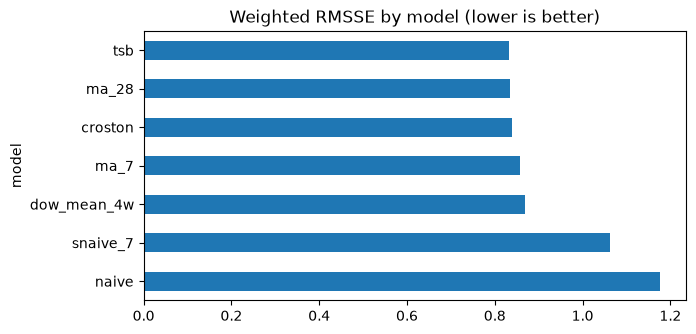

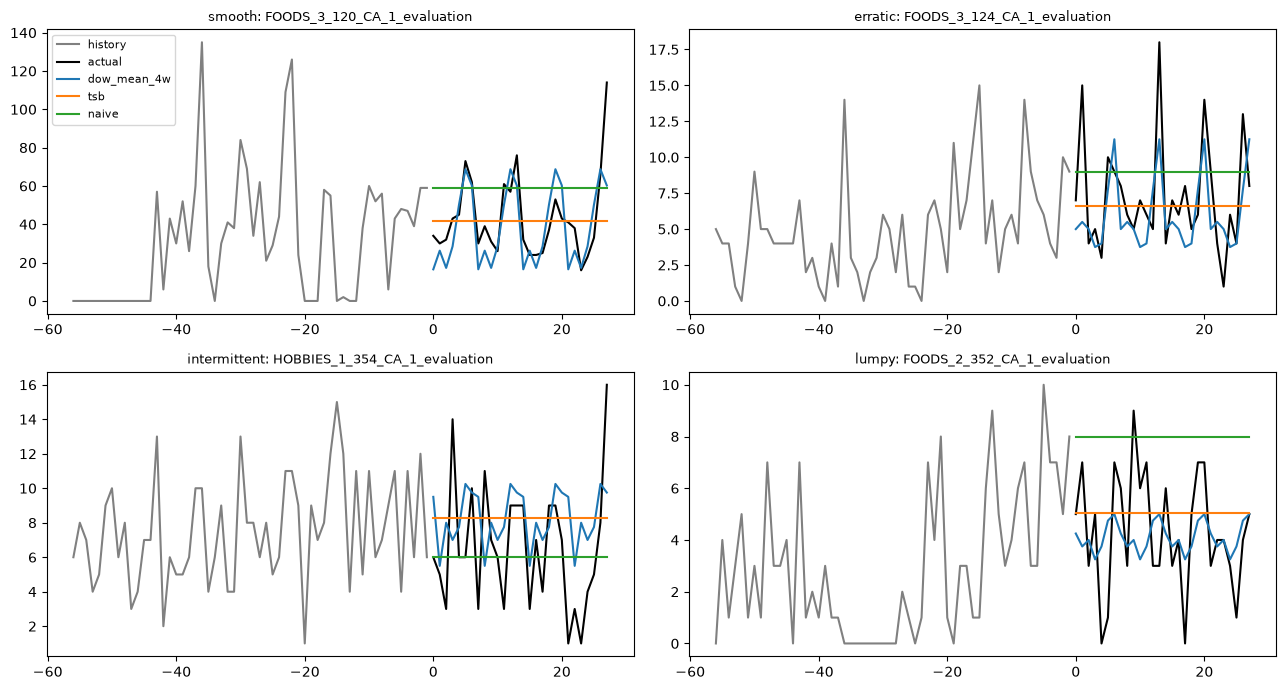

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.5))
summary["wrmsse"].sort_values(ascending=False).plot.barh(ax=ax)
ax.set_title("Weighted RMSSE by model (lower is better)")
fig.savefig(FIG / "04_baseline_wrmsse.png", dpi=150, bbox_inches="tight")

# one example series per demand class, last fold
o = origins[-1]
show = ["dow_mean_4w", "tsb", "naive"]
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
w_last = (Y[:, o - 28:o] * np.nan_to_num(P[:, o - 28:o])).sum(axis=1)
forecasts = {m: models[m](Y[:, :o]) for m in show}
for ax, cls in zip(axes.ravel(), ["smooth", "erratic", "intermittent", "lumpy"]):
    idx = np.flatnonzero(classes.to_numpy() == cls)
    if len(idx) == 0:
        ax.set_title(f"{cls}: no series"); continue
    i = idx[np.argmax(w_last[idx])]
    x_tr = np.arange(-56, 0); x_te = np.arange(0, H)
    ax.plot(x_tr, Y[i, o - 56:o], color="grey", label="history")
    ax.plot(x_te, Y[i, o:o + H], color="black", label="actual")
    for m in show:
        ax.plot(x_te, forecasts[m][i], label=m)
    ax.set_title(f"{cls}: {ids[i]}", fontsize=9)
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "05_example_forecasts.png", dpi=150, bbox_inches="tight")

## Takeaways (fill in)
- Best overall model and its weighted RMSSE:
- Does Croston/TSB beat the weekday mean on intermittent and lumpy series?
- Is any model stable across all 5 folds, or does it swing?
- Which model over- or under-forecasts (bias)?
- Target for LightGBM: beat ______ on weighted RMSSE.